# Arabic Poetry GPT — a tokenizer and width study

Four experiments on a corpus of ~55k classical Arabic verses:

1. **Compression baselines** — what does a bits-per-character number actually mean
2. **Merge sweep** — model quality vs how many times BPE glued symbols together
3. **The 2D grid** — `(vocab_size, n_embd)` jointly, on two surfaces, 3 seeds
4. **The 2×2** — tashkeel × tokenizer, sampled with the prompt **سميرة**

### The one methodological rule

Cross-entropy per *token* is **not comparable across tokenizers**. An untrained
model scores `ln(34)=3.53` on a char vocab and `ln(2048)=7.63` on a BPE vocab,
and that bias does **not** vanish with training — it's a units problem, not a
baseline offset. Everything below is therefore in **bits per character**:

$$\mathrm{BPC} = \mathcal{L}_{\text{nats/token}} \times \frac{N_{\text{tokens}}}{N_{\text{chars}}} \times \frac{1}{\ln 2}$$

This is exact because the tokenizer is lossless: by the chain rule
$-\log P(\text{corpus})$ is the same number however you chop the text up.

**Runtime:** ~60–90 min on a T4. Set `QUICK = True` for a ~10 min smoke run.

In [17]:
import torch, math, time, os
print("torch", torch.__version__)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)
if DEVICE == "cuda":
    print(torch.cuda.get_device_name(0))
else:
    print("!! No GPU. Runtime > Change runtime type > T4 GPU")

QUICK = False          # True -> tiny grid, ~10 min, for checking it runs
SEEDS = [0, 1, 2]
ITERS = 10000

torch 2.11.0+cu128
device: cuda
NVIDIA L4


## 1. Data

Source: [ARBML/MetRec](https://github.com/ARBML/MetRec) (MIT) — ~55k classical
verses scraped from الديوان, originally labelled by meter. We drop the labels.

Two variants are produced: with and without **tashkeel** (the short-vowel marks).

In [2]:
import io, re, tarfile, unicodedata, urllib.request, zipfile
from collections import Counter

TASHKEEL = re.compile(r"[\u0610-\u061A\u064B-\u065F\u0670\u06D6-\u06ED]")
TATWEEL  = "\u0640"
ARABIC   = "\u0621-\u063A\u0641-\u064A\u0671"
ALLOWED  = re.compile(rf"[^{ARABIC}\u064B-\u0652\u0670 #]")
ORPHAN   = re.compile(r"(?:(?<=^)|(?<=\s))[\u0610-\u061A\u064B-\u065F\u0670\u06D6-\u06ED]+")

def fetch():
    if os.path.exists("_train.txt"): return
    print("downloading MetRec ...")
    raw = urllib.request.urlopen(
        "https://codeload.github.com/ARBML/MetRec/tar.gz/refs/heads/master").read()
    with tarfile.open(fileobj=io.BytesIO(raw), mode="r:gz") as tar:
        mem = next(m for m in tar.getmembers() if m.name.endswith("baits.zip"))
        inner = tar.extractfile(mem).read()
    with zipfile.ZipFile(io.BytesIO(inner)) as z:
        open("_train.txt","wb").write(z.read("final_baits/train.txt"))
        open("_test.txt","wb").write(z.read("final_baits/test.txt"))
    print("ok")

def clean(line, keep_dia):
    line = re.sub(r"^\s*\d+\s+", "", line)          # strip meter label
    line = unicodedata.normalize("NFKC", line).replace(TATWEEL, "")
    if keep_dia:
        line = ORPHAN.sub("", line)   # marks with no base letter (scrape junk)
    else:
        line = TASHKEEL.sub("", line)
    line = re.sub("[إأآٱ]", "ا", line)
    line = line.replace("ى","ي").replace("ة","ه")
    line = ALLOWED.sub(" ", line)
    return re.sub(r"\s+", " ", line).strip()

def build(keep_dia, out):
    fetch(); seen, rows = set(), []
    for p in ("_train.txt","_test.txt"):
        for ln in open(p, encoding="utf-8"):
            v = clean(ln, keep_dia)
            if "#" not in v: continue
            a, _, b = v.partition("#")
            if len(a.split()) < 2 or len(b.split()) < 2: continue
            if v in seen: continue
            seen.add(v); rows.append(v)
    txt = "\n".join(rows) + "\n"
    open(out, "w", encoding="utf-8").write(txt)
    print(f"{out}: {len(rows):,} verses, {len(txt):,} chars, vocab {len(set(txt))}")
    return txt

TEXT_PLAIN = build(False, "arabic_poems.txt")
TEXT_TASH  = build(True,  "arabic_poems_tashkeel.txt")
print()
print(TEXT_PLAIN[:200])

downloading MetRec ...
ok
arabic_poems.txt: 55,075 verses, 2,653,532 chars, vocab 34
arabic_poems_tashkeel.txt: 55,248 verses, 3,439,922 chars, vocab 42

يا ضيف طيف ما هداه لمضجعي # الا لهيب في الحشي يتوقد
امامك الصبح كم يشكو دجي ووجي # فظاظه الشوك قد تفضي الي الرطب
وعيون نرجه لنحوك قد رنت # وغدت تشير اليك بالايماء
قطعت مكاتبتي عنكم # لاجل حديث اليكم ي


## 2. Tokenizers

**Grapheme clustering first.** Arabic diacritics are *combining* codepoints:
`كَتَبَ` is 6 codepoints but 3 visible letters. A char model wastes half its
context on marks. So each base letter is glued to its trailing marks and that
becomes the atom BPE operates on.

Then ordinary BPE merges the most frequent adjacent pair, repeatedly.

Because the corpus is inconsistently vocalised, BPE learns **both** marked and
unmarked forms of the same word as separate tokens — which is the behaviour we
want, for free.

In [3]:
COMBINING = "\u0610-\u061A\u064B-\u065F\u0670\u06D6-\u06ED"
# 2nd alternative catches ORPHAN marks so encode/decode round-trips exactly
CLUSTER_RE = re.compile(rf"[^{COMBINING}][{COMBINING}]*|[{COMBINING}]+")

def to_clusters(s): return CLUSTER_RE.findall(s)

class CharTokenizer:
    def __init__(self, text):
        self.vocab = sorted(set(text))
        self.stoi = {c:i for i,c in enumerate(self.vocab)}
        self.itos = {i:c for i,c in enumerate(self.vocab)}
    def encode(self, s): return [self.stoi[c] for c in s if c in self.stoi]
    def decode(self, ids): return "".join(self.itos[i] for i in ids)
    @property
    def vocab_size(self): return len(self.vocab)
    @property
    def merges(self): return []

class ArabicBPE:
    def __init__(self, vocab, merges):
        self.vocab, self.merges = vocab, merges
        self.stoi = {t:i for i,t in enumerate(vocab)}
        self.ranks = {p:i for i,p in enumerate(merges)}
    @property
    def vocab_size(self): return len(self.vocab)

    @classmethod
    def train(cls, text, vocab_size=2048, verbose=False):
        words  = Counter(text.split())
        splits = {w: tuple(to_clusters(w)) for w in words}
        alpha  = sorted({c for sp in splits.values() for c in sp})
        vocab  = ["\n"," "] + [c for c in alpha if c not in ("\n"," ")]
        merges = []
        # incremental pair counts + an index pair -> words, otherwise this is
        # O(merges x corpus) and takes forever
        pairs, where = Counter(), {}
        for w,f in words.items():
            sp = splits[w]
            for i in range(len(sp)-1):
                p = (sp[i],sp[i+1]); pairs[p]+=f; where.setdefault(p,set()).add(w)
        while len(vocab) < vocab_size and pairs:
            best,cnt = pairs.most_common(1)[0]
            if cnt < 2: break
            a,b = best; new = a+b
            merges.append(best); vocab.append(new)
            for w in list(where.get(best,())):
                sp,f = splits[w], words[w]
                for i in range(len(sp)-1):
                    p=(sp[i],sp[i+1]); pairs[p]-=f
                    if pairs[p]<=0: pairs.pop(p,None); where.pop(p,None)
                    elif p in where: where[p].discard(w)
                out,i=[],0
                while i < len(sp):
                    if i<len(sp)-1 and sp[i]==a and sp[i+1]==b: out.append(new); i+=2
                    else: out.append(sp[i]); i+=1
                sp = tuple(out); splits[w]=sp
                for i in range(len(sp)-1):
                    p=(sp[i],sp[i+1]); pairs[p]+=f; where.setdefault(p,set()).add(w)
            pairs.pop(best,None); where.pop(best,None)
        return cls(vocab, merges)

    def _word(self, w):
        sp = to_clusters(w)
        while len(sp) > 1:
            best, br = None, None
            for i in range(len(sp)-1):
                r = self.ranks.get((sp[i],sp[i+1]))
                if r is not None and (br is None or r < br): best, br = i, r
            if best is None: break
            sp = sp[:best] + [sp[best]+sp[best+1]] + sp[best+2:]
        return sp
    def _emit(self, tok, ids):
        # A cluster never seen in training (e.g. a vocalised prompt fed to a
        # tokenizer fitted on unvocalised text) is not in the vocab. Fall back
        # to its individual codepoints, then drop anything still unknown,
        # rather than raising. In-domain text is unaffected and still
        # round-trips exactly.
        if tok in self.stoi: ids.append(self.stoi[tok]); return
        for ch in tok:
            if ch in self.stoi: ids.append(self.stoi[ch])

    def encode(self, text):
        ids=[]
        for j,line in enumerate(text.split("\n")):
            if j: ids.append(self.stoi["\n"])
            for k,w in enumerate(line.split(" ")):
                if k: ids.append(self.stoi[" "])
                for t in self._word(w): self._emit(t, ids)
        return ids
    def decode(self, ids): return "".join(self.vocab[i] for i in ids)

# --- round-trip check. this matters twice: it stops silent data loss, AND it
# --- is what makes the BPC conversion mathematically exact.
_t = ArabicBPE.train(TEXT_PLAIN[:200000], 512)
assert _t.decode(_t.encode(TEXT_PLAIN[:5000])) == TEXT_PLAIN[:5000]
print("round-trip ok |", [_t.vocab[i] for i in _t.encode("وقال الشاعر سميره")])
assert _t.encode("وَالعَلياءِ")  # OOV clusters degrade, do not raise

round-trip ok | ['وق', 'ال', ' ', 'الش', 'اع', 'ر', ' ', 'سم', 'ير', 'ه']


In [4]:
!pip -q install datasets
import datasets
from prepare_ashaar import build_corpus, CLASSICAL_ERAS   # upload this file

ashaar = datasets.load_dataset("arbml/ashaar", split="train")
print(ashaar)                      # inspect columns before trusting anything

TEXT_POEMS, stats = build_corpus(
    ashaar,
    keep_diacritics=False,
    conditioning=True,       # prepend [meter|theme] so you can prompt with it
    eras=None,               # or CLASSICAL_ERAS for a pre-modern subset
    min_baits=3, max_baits=60,
    limit=200000,             # start here; None = all 254k poems
)
print(stats)
open("arabic_poems_structured.txt", "w", encoding="utf-8").write(TEXT_POEMS)
print(TEXT_POEMS[:400])

README.md:   0%|          | 0.00/4.71k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/34.7k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  126MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  151MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/254630 [00:00<?, ? examples/s]

Dataset({
    features: ['poem title', 'poem meter', 'poem verses', 'poem theme', 'poem url', 'poet name', 'poet description', 'poet url', 'poet era', 'poet location', 'poem description', 'poem language type'],
    num_rows: 254630
})
{'seen': 254630, 'kept': 199770, 'no_meter': 0, 'odd': 24378, 'too_short': 54860, 'too_long': 7365, 'wrong_era': 0, 'baits': 3186831, 'chars': 161956130, 'vocab': 39}
[الخفيف|دينية]
اصبح الملك للذي فطر الخل # ق بتقدير للعزيز العليم
غافر الذنب للمسيء بعفو # قابل التوب ذي العطاء العميم
مرسل المصطفي البشير الينا # رحمه منه بالكلام القديم
ربنا ربنا اليك انينا # فاجرنا من حر نار الجحيم
واكفنا شر ما نخاف بلطف # يا عظيما يرجي لكل عظيم
وتقبل اعمالنا واعف عنا # وانلنا دخول دار النعيم
بنبي بعثته فهدانا # لصراط من الهدي مستقيم
وبمن نحن في حماه مدي الدهر # اخيه يحيي الحصور


## 3. What does BPC mean? Compression baselines

Cross-entropy *is* code length (Shannon): a model at 3.4 BPC would compress this
text to 3.4 bits per character in an arithmetic coder. So classical compressors
are directly comparable, and they anchor the numbers.

In [5]:
import gzip, bz2, lzma
def baselines(text, name):
    raw, n = text.encode("utf-8"), len(text)
    rows = [("utf-8 on disk", len(raw)*8/n),
            ("uniform over vocab", math.log2(len(set(text))))]
    for nm, mod in [("gzip",gzip),("bzip2",bz2),("lzma",lzma)]:
        rows.append((nm, len(mod.compress(raw))*8/n))
    print(f"--- {name} ({n:,} chars) ---")
    for k,v in rows: print(f"  {k:20s} {v:6.2f} bits/char")
    return dict(rows)

BASE_PLAIN = baselines(TEXT_PLAIN, "no tashkeel")
BASE_TASH  = baselines(TEXT_TASH,  "tashkeel")

--- no tashkeel (2,653,532 chars) ---
  utf-8 on disk         14.16 bits/char
  uniform over vocab     5.09 bits/char
  gzip                   4.65 bits/char
  bzip2                  3.44 bits/char
  lzma                   3.66 bits/char
--- tashkeel (3,439,922 chars) ---
  utf-8 on disk         14.58 bits/char
  uniform over vocab     5.39 bits/char
  gzip                   4.85 bits/char
  bzip2                  3.49 bits/char
  lzma                   3.67 bits/char


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 4. Model

Standard nanoGPT: pre-norm blocks, residual connections, weight tying.
`factor_rank` optionally switches on ALBERT-style factorised embeddings, which
decouple vocabulary size from hidden width.

In [22]:
import math, json, os, time, itertools
import torch, torch.nn as nn, torch.nn.functional as F

# ============================================================ model
class Head(nn.Module):
  def __init__(s, ne, hs, bs, dr):
    super().__init__()
    s.key = nn.Linear(ne, hs, bias=False)
    s.query = nn.Linear(ne, hs, bias=False)
    s.value = nn.Linear(ne, hs, bias=False)
    s.register_buffer('tril', torch.tril(torch.ones(bs, bs)))
    s.drop = nn.Dropout(dr)
  def forward(s, x):
    B, T, C = x.shape
    k, q, v = s.key(x), s.query(x), s.value(x)
    w = q @ k.transpose(-2, -1) * k.shape[-1] ** -0.5
    w = w.masked_fill(s.tril[:T, :T] == 0, float('-inf'))
    return s.drop(F.softmax(w, -1)) @ v

class MultiHead(nn.Module):
  def __init__(s, ne, nh, bs, dr):
    super().__init__()
    hs = ne // nh
    s.heads = nn.ModuleList([Head(ne, hs, bs, dr) for _ in range(nh)])
    s.proj = nn.Linear(nh * hs, ne); s.drop = nn.Dropout(dr)
  def forward(s, x):
    return s.drop(s.proj(torch.cat([h(x) for h in s.heads], -1)))

class FeedForward(nn.Module):
  def __init__(s, ne, dr):
    super().__init__()
    s.net = nn.Sequential(nn.Linear(ne, 4*ne), nn.ReLU(),
                          nn.Linear(4*ne, ne), nn.Dropout(dr))
  def forward(s, x): return s.net(x)

class Block(nn.Module):
  def __init__(s, ne, nh, bs, dr):
    super().__init__()
    s.sa = MultiHead(ne, nh, bs, dr); s.ff = FeedForward(ne, dr)
    s.ln1 = nn.LayerNorm(ne); s.ln2 = nn.LayerNorm(ne)
  def forward(s, x):
    x = x + s.sa(s.ln1(x)); x = x + s.ff(s.ln2(x)); return x

class GPT(nn.Module):
  """factor_rank=None -> normal tied embedding.
     factor_rank=r    -> ALBERT-style factorised embedding (vocab x r, r x ne),
                         which decouples vocab size from hidden width."""
  def __init__(s, vocab, ne, nh, nl, bs, dr=0.1, factor_rank=None):
    super().__init__()
    s.bs = bs; s.factor_rank = factor_rank
    if factor_rank:
      s.tok = nn.Embedding(vocab, factor_rank)
      s.tok_proj = nn.Linear(factor_rank, ne, bias=False)
    else:
      s.tok = nn.Embedding(vocab, ne); s.tok_proj = None
    s.pos = nn.Embedding(bs, ne)
    s.blocks = nn.Sequential(*[Block(ne, nh, bs, dr) for _ in range(nl)])
    s.ln_f = nn.LayerNorm(ne)
    s.lm_head = nn.Linear(ne, vocab)
    if not factor_rank:
      s.lm_head.weight = s.tok.weight          # weight tying
    s.apply(s._init)
  def _init(s, m):
    if isinstance(m, nn.Linear):
      nn.init.normal_(m.weight, 0.0, 0.02)
      if m.bias is not None: nn.init.zeros_(m.bias)
    elif isinstance(m, nn.Embedding):
      nn.init.normal_(m.weight, 0.0, 0.02)
  def forward(s, idx, targets=None):
    e = s.tok(idx)
    if s.tok_proj is not None: e = s.tok_proj(e)
    x = e + s.pos(torch.arange(idx.shape[1], device=idx.device))
    x = s.ln_f(s.blocks(x)); logits = s.lm_head(x)
    loss = None
    if targets is not None:
      B, T, C = logits.shape
      loss = F.cross_entropy(logits.view(B*T, C), targets.view(B*T))
    return logits, loss
  @torch.no_grad()
  def generate(s, idx, n, temperature=1.0, top_k=None):
    for _ in range(n):
      logits, _ = s(idx[:, -s.bs:])
      logits = logits[:, -1, :] / temperature
      if top_k:
        v, _ = torch.topk(logits, min(top_k, logits.shape[-1]))
        logits[logits < v[:, [-1]]] = -float('inf')
      idx = torch.cat((idx, torch.multinomial(F.softmax(logits, -1), 1)), 1)
    return idx

# ============================================================ metric
def bpc(loss_nats, n_tokens, n_chars):
  """Convert per-token cross-entropy (nats) into bits per CHARACTER.

  Because the tokenizer is lossless and deterministic, the chain rule gives
      -log P(corpus) = sum_i -log P(t_i | t_<i) = loss * n_tokens
  which is a tokenizer-INDEPENDENT quantity.  Dividing by n_chars puts every
  tokenizer on the same footing; /ln2 converts nats to bits."""
  return loss_nats * (n_tokens / n_chars) / math.log(2)

def count_params(m, vocab, ne, factor_rank=None):
  total = sum(p.numel() for p in m.parameters())
  emb = vocab * (factor_rank or ne) + (factor_rank * ne if factor_rank else 0)
  return total, total - emb

# ============================================================ training
def train_one(ids, n_chars, vocab, ne, nh, nl, bs=128, batch=32, dr=0.1,
              lr=3e-4, iters=800, eval_iters=25, eval_every=200,
              factor_rank=None, seed=0, device="cuda", log=False):
  torch.manual_seed(seed)
  data = torch.tensor(ids, dtype=torch.long)
  n = int(len(data) * 0.9)
  tr, va = data[:n].to(device), data[n:].to(device)
  ratio = len(ids) / n_chars

  def batch_of(split):
    d = tr if split == "train" else va
    ix = torch.randint(len(d) - bs - 1, (batch,), device=device)
    x = torch.stack([d[i:i+bs] for i in ix])
    y = torch.stack([d[i+1:i+bs+1] for i in ix])
    return x, y

  @torch.no_grad()
  def evaluate():
    m.eval(); out = {}
    for sp in ("train", "val"):
      L = torch.zeros(eval_iters)
      for k in range(eval_iters):
        X, Y = batch_of(sp); _, L[k] = m(X, Y)
      out[sp] = L.mean().item()
    m.train(); return out

  m = GPT(vocab, ne, nh, nl, bs, dr, factor_rank).to(device)
  total, nonemb = count_params(m, vocab, ne, factor_rank)
  opt = torch.optim.AdamW(m.parameters(), lr=lr)
  hist, t0 = [], time.time()
  PROG = max(1, iters // 200)        # ~200 updates per run
  for it in range(iters + 1):
    if it % eval_every == 0 or it == iters:
      L = evaluate()
      hist.append(dict(iter=it, val=L["val"], train=L["train"],
                       bpc_val=bpc(L["val"], len(ids), n_chars),
                       bpc_train=bpc(L["train"], len(ids), n_chars)))
      if log: print(f"\n      it{it:5d} {hist[-1]['bpc_val']:.4f} bpc")
    if it and it % PROG == 0:
      el = time.time() - t0
      print(f"\r  {100*it/iters:5.1f}%  {it}/{iters}  "
            f"{el/60:.1f}m elapsed, ~{el*(iters-it)/it/60:.0f}m left",
            end="", flush=True)
    if it == iters: break
    X, Y = batch_of("train")
    _, loss = m(X, Y)
    opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
  return dict(model=m, hist=hist, final=hist[-1], params=total,
              nonembed=nonemb, ratio=ratio, secs=time.time()-t0)


def pick_layers_for_budget(vocab, ne, budget, bs=128, factor_rank=None,
                           lo=1, hi=10):
  """Choose n_layer so total params land as close as possible to `budget`.
  This is how the parameter-matched surface is built: capacity is held fixed
  so that vocabulary size is the only thing varying."""
  best, best_err = None, None
  for nl in range(lo, hi + 1):
    nh = max(1, ne // 64)
    m = GPT(vocab, ne, nh, nl, bs, 0.0, factor_rank)
    tot, _ = count_params(m, vocab, ne, factor_rank)
    err = abs(tot - budget)
    if best_err is None or err < best_err:
      best, best_err = nl, err
    del m
  return best

## 5. Study 1 — the merge sweep

How does quality depend on **how many times BPE joined two symbols**?
`merges = 0` is plain character level.

The tokenizer is fit on the **train split only** — fitting it on the whole
corpus would leak validation text into the vocabulary.

In [ ]:
import numpy as np, json

VOCABS_1D = [256, 512, 1024, 2048, 4096] if not QUICK else [256, 1024]
seeds_1d  = SEEDS if not QUICK else [0]
iters_1d  = ITERS if not QUICK else 200

text = TEXT_PLAIN
train_text = text[:int(len(text)*0.9)]
TOKCACHE = {}

def get_tok(v, txt=None):
    if v == "char": return CharTokenizer(text)
    if v not in TOKCACHE:
        t0=time.time()
        TOKCACHE[v] = ArabicBPE.train(txt or train_text, vocab_size=v)
        print(f"  bpe {v}: {len(TOKCACHE[v].merges)} merges ({time.time()-t0:.0f}s)")
    return TOKCACHE[v]

rows1 = []
for v in ["char"] + VOCABS_1D:
    tok = get_tok(v)
    ids = tok.encode(text)
    cpt = len(text)/len(ids)
    bs, per_seed = [], []
    for sd in seeds_1d:
        r = train_one(ids, len(text), tok.vocab_size, 192, 3, 4,
                      bs=128, batch=32, iters=iters_1d, eval_every=iters_1d//4,
                      seed=sd, device=DEVICE)
        per_seed.append(r["final"]["bpc_val"]); bs.append(r)
    rows1.append(dict(label=str(v), vocab=tok.vocab_size,
                      merges=len(tok.merges), chars_per_token=cpt,
                      bpc=float(np.mean(per_seed)), std=float(np.std(per_seed)),
                      params=bs[0]["params"], nonembed=bs[0]["nonembed"],
                      hist=bs[0]["hist"], seeds=per_seed))
    print(f"{str(v):>6}: {len(tok.merges):5d} merges  {cpt:.2f} c/tok  "
          f"{np.mean(per_seed):.4f} +/- {np.std(per_seed):.4f} bpc")

json.dump(rows1, open("study1.json","w"))

  char:     0 merges  1.00 c/tok  3.2008 +/- 0.0087 bpc
  bpe 256: 222 merges (3s)
   256:   222 merges  1.46 c/tok  3.1391 +/- 0.0004 bpc
  bpe 512: 478 merges (3s)
   512:   478 merges  1.57 c/tok  3.1516 +/- 0.0212 bpc
  bpe 1024: 990 merges (4s)
  1024:   990 merges  1.68 c/tok  3.1790 +/- 0.0136 bpc
  bpe 2048: 2014 merges (8s)
  2048:  2014 merges  1.79 c/tok  3.1685 +/- 0.0090 bpc
  bpe 4096: 4062 merges (16s)
  4096:  4062 merges  1.89 c/tok  3.1092 +/- 0.0066 bpc


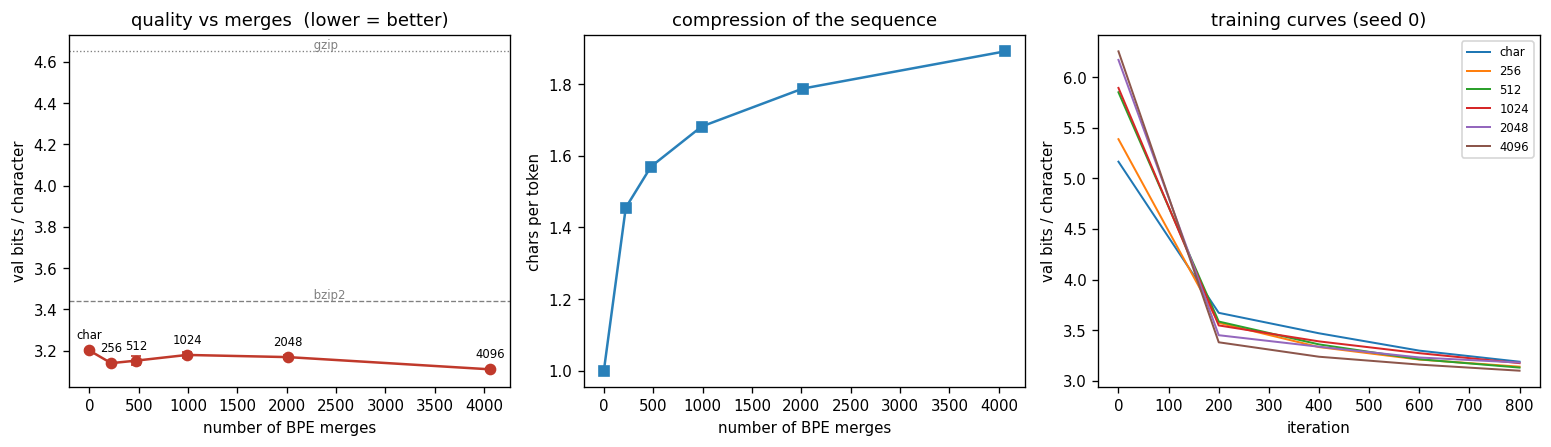

In [ ]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi":120, "font.size":9})

fig, ax = plt.subplots(1, 3, figsize=(13,3.8))
m   = [r["merges"] for r in rows1]
b   = [r["bpc"] for r in rows1]
e   = [r["std"] for r in rows1]
cpt = [r["chars_per_token"] for r in rows1]

ax[0].errorbar(m, b, yerr=e, marker="o", capsize=3, color="#c0392b")
for r in rows1:
    ax[0].annotate(r["label"], (r["merges"], r["bpc"]),
                   textcoords="offset points", xytext=(0,7), ha="center", fontsize=7)
ax[0].axhline(BASE_PLAIN["bzip2"], ls="--", lw=.8, c="gray")
ax[0].text(max(m)*.55, BASE_PLAIN["bzip2"], " bzip2", fontsize=7, c="gray", va="bottom")
ax[0].axhline(BASE_PLAIN["gzip"], ls=":", lw=.8, c="gray")
ax[0].text(max(m)*.55, BASE_PLAIN["gzip"], " gzip", fontsize=7, c="gray", va="bottom")
ax[0].set_xlabel("number of BPE merges"); ax[0].set_ylabel("val bits / character")
ax[0].set_title("quality vs merges  (lower = better)")

ax[1].plot(m, cpt, marker="s", color="#2980b9")
ax[1].set_xlabel("number of BPE merges"); ax[1].set_ylabel("chars per token")
ax[1].set_title("compression of the sequence")

for r in rows1:
    ax[2].plot([h["iter"] for h in r["hist"]],
               [h["bpc_val"] for h in r["hist"]], label=r["label"], lw=1.2)
ax[2].set_xlabel("iteration"); ax[2].set_ylabel("val bits / character")
ax[2].set_title("training curves (seed 0)"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig("fig1_merges.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Study 2 — the 2D grid

### Why a grid and not two sequential searches

Minimising over `vocab` at fixed `n_embd`, then over `n_embd` at fixed `vocab`,
is **coordinate descent**. It reaches the joint minimum only if the two
variables don't interact — i.e. if the valley of the loss surface runs parallel
to an axis. If the valley runs *diagonally*, coordinate descent stalls at a
point that is optimal along each axis separately and optimal in neither jointly.

Here there is a concrete mechanism forcing a diagonal valley: the **softmax
bottleneck**. `lm_head` maps `n_embd → vocab_size`, so the matrix of achievable
log-probabilities has rank at most `n_embd`. A larger vocabulary genuinely
*requires* a larger `n_embd` to be representable. The parameters are coupled by
construction, so we sweep them jointly and look at whether the ridge tilts.

### Two surfaces

- **raw** — `n_layer` fixed. Bigger vocab ⇒ more parameters. Honest but confounded.
- **parameter-matched** — `n_layer` chosen per cell so total parameters land near
  a fixed budget. Capacity held constant, so vocabulary is the only thing varying.

In [ ]:
VOCAB_GRID = ["char", 512, 1024, 2048, 4096] if not QUICK else ["char", 1024]
EMBD_GRID  = [64, 128, 192, 256, 384]        if not QUICK else [64, 128]
seeds_2d   = SEEDS if not QUICK else [0]
iters_2d   = ITERS if not QUICK else 150
BUDGET     = 3_000_000

grid = {}
total_runs = len(VOCAB_GRID)*len(EMBD_GRID)*len(seeds_2d)*2
done, t_start = 0, time.time()

for surface in ("raw", "matched"):
    for v in VOCAB_GRID:
        tok = get_tok(v); ids = tok.encode(text)
        for ne in EMBD_GRID:
            nh = max(1, ne // 64)
            nl = 4 if surface == "raw" else pick_layers_for_budget(
                     tok.vocab_size, ne, BUDGET, bs=128)
            vals = []
            for sd in seeds_2d:
                r = train_one(ids, len(text), tok.vocab_size, ne, nh, nl,
                              bs=128, batch=32, iters=iters_2d,
                              eval_every=iters_2d, seed=sd, device=DEVICE)
                vals.append(r["final"]["bpc_val"]); done += 1
            grid[(surface, str(v), ne)] = dict(
                bpc=float(np.mean(vals)), std=float(np.std(vals)),
                n_layer=nl, params=r["params"], nonembed=r["nonembed"],
                vocab=tok.vocab_size, seeds=vals)
            el = time.time()-t_start
            print(f"[{done:3d}/{total_runs}] {surface:8s} v={str(v):>4} d={ne:3d} "
                  f"L={nl} -> {np.mean(vals):.4f} +/- {np.std(vals):.4f} bpc "
                  f"| {el/60:.1f}m elapsed, ~{el/done*(total_runs-done)/60:.0f}m left")

json.dump({f"{k[0]}|{k[1]}|{k[2]}":val for k,val in grid.items()},
          open("study2.json","w"))

[  3/150] raw      v=char d= 64 L=4 -> 3.4792 +/- 0.0030 bpc | 0.7m elapsed, ~32m left
[  6/150] raw      v=char d=128 L=4 -> 3.3198 +/- 0.0029 bpc | 1.5m elapsed, ~36m left
[  9/150] raw      v=char d=192 L=4 -> 3.2045 +/- 0.0157 bpc | 2.8m elapsed, ~43m left
[ 12/150] raw      v=char d=256 L=4 -> 3.0994 +/- 0.0074 bpc | 4.5m elapsed, ~52m left
[ 15/150] raw      v=char d=384 L=4 -> 3.0670 +/- 0.0168 bpc | 7.9m elapsed, ~71m left
[ 18/150] raw      v= 512 d= 64 L=4 -> 3.4795 +/- 0.0057 bpc | 8.6m elapsed, ~63m left
[ 21/150] raw      v= 512 d=128 L=4 -> 3.2250 +/- 0.0067 bpc | 9.4m elapsed, ~58m left
[ 24/150] raw      v= 512 d=192 L=4 -> 3.1360 +/- 0.0072 bpc | 10.7m elapsed, ~56m left
[ 27/150] raw      v= 512 d=256 L=4 -> 3.0972 +/- 0.0061 bpc | 12.5m elapsed, ~57m left
[ 30/150] raw      v= 512 d=384 L=4 -> 3.0521 +/- 0.0098 bpc | 15.9m elapsed, ~64m left
[ 33/150] raw      v=1024 d= 64 L=4 -> 3.4438 +/- 0.0100 bpc | 16.6m elapsed, ~59m left
[ 36/150] raw      v=1024 d=128 L=4 -> 

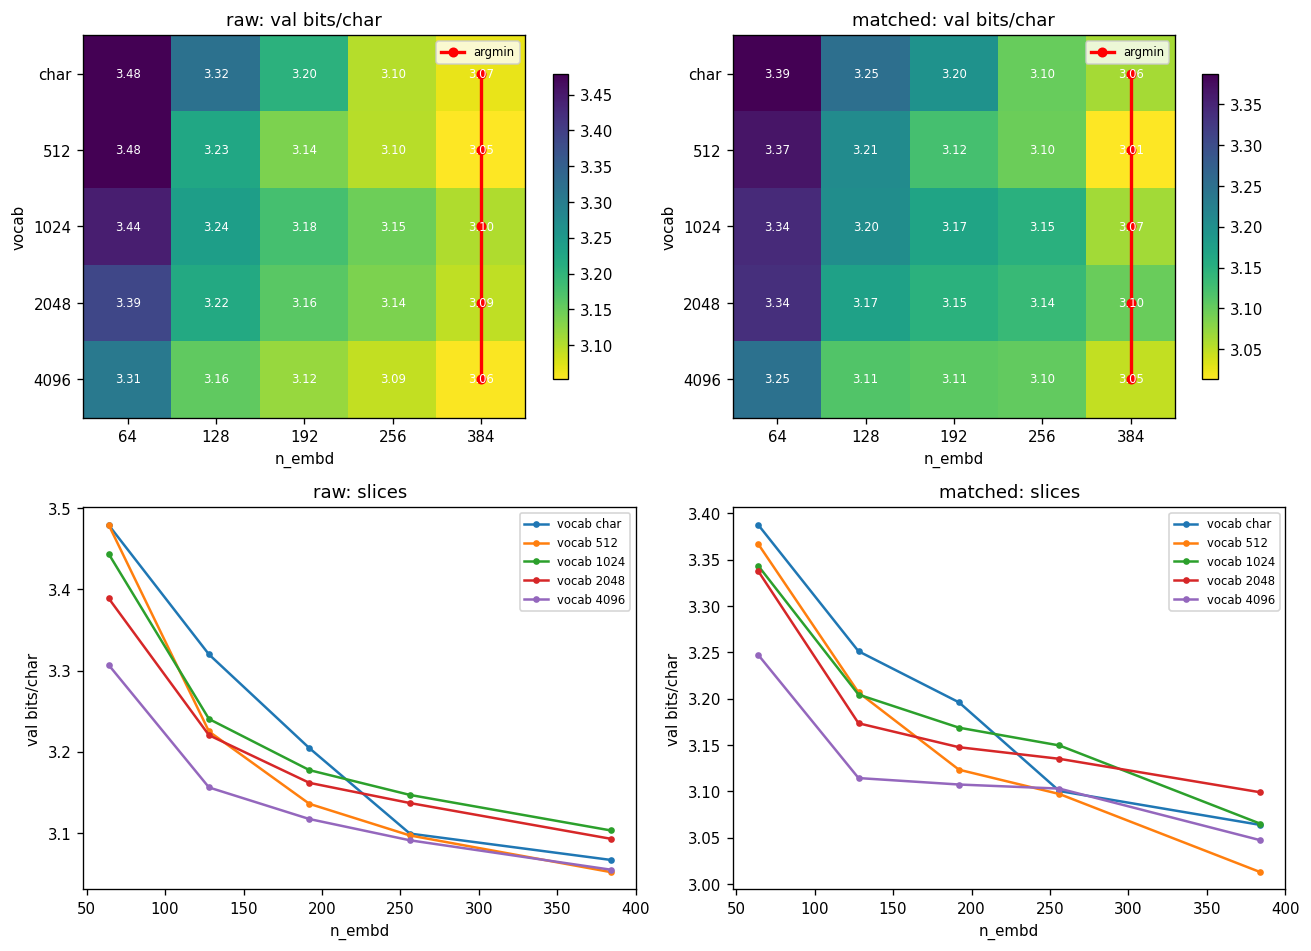


Does the optimal n_embd move with vocab size?

  raw:
    vocab char: best n_embd = 384  (within 1sd: [384])  min=3.0670 sd=0.0168
    vocab  512: best n_embd = 384  (within 1sd: [384])  min=3.0521 sd=0.0098
    vocab 1024: best n_embd = 384  (within 1sd: [384])  min=3.1033 sd=0.0026
    vocab 2048: best n_embd = 384  (within 1sd: [384])  min=3.0930 sd=0.0002
    vocab 4096: best n_embd = 384  (within 1sd: [384])  min=3.0550 sd=0.0082
    coordinate-descent best 3.0521 vs joint best 3.0521 -> gap +0.0000 bpc

  matched:
    vocab char: best n_embd = 384  (within 1sd: [384])  min=3.0638 sd=0.0059
    vocab  512: best n_embd = 384  (within 1sd: [384])  min=3.0129 sd=0.0132
    vocab 1024: best n_embd = 384  (within 1sd: [384])  min=3.0652 sd=0.0111
    vocab 2048: best n_embd = 384  (within 1sd: [384])  min=3.0990 sd=0.0022
    vocab 4096: best n_embd = 384  (within 1sd: [384])  min=3.0473 sd=0.0081
    coordinate-descent best 3.0129 vs joint best 3.0129 -> gap +0.0000 bpc



In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for col, surface in enumerate(("raw","matched")):
    M = np.array([[grid[(surface,str(v),ne)]["bpc"] for ne in EMBD_GRID]
                  for v in VOCAB_GRID])
    ax = axes[0, col]
    im = ax.imshow(M, cmap="viridis_r", aspect="auto")
    ax.set_xticks(range(len(EMBD_GRID)), EMBD_GRID)
    ax.set_yticks(range(len(VOCAB_GRID)), [str(v) for v in VOCAB_GRID])
    ax.set_xlabel("n_embd"); ax.set_ylabel("vocab")
    ax.set_title(f"{surface}: val bits/char")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i,j]:.2f}", ha="center", va="center",
                    fontsize=7, color="w")
    # the ridge: best n_embd for each vocab. if this tilts, the two
    # parameters interact and sequential optimisation is invalid.
    best = M.argmin(axis=1)
    ax.plot(best, range(len(VOCAB_GRID)), "r-o", lw=2, ms=5, label="argmin")
    ax.legend(fontsize=7)
    plt.colorbar(im, ax=ax, shrink=.8)

    ax2 = axes[1, col]
    for i, v in enumerate(VOCAB_GRID):
        ax2.plot(EMBD_GRID, M[i], marker="o", ms=3, label=f"vocab {v}")
    ax2.set_xlabel("n_embd"); ax2.set_ylabel("val bits/char")
    ax2.set_title(f"{surface}: slices"); ax2.legend(fontsize=7)

plt.tight_layout(); plt.savefig("fig2_grid.png", dpi=150, bbox_inches="tight")
plt.show()

# --- is the ridge actually tilted, or is it noise?
print("\nDoes the optimal n_embd move with vocab size?\n")
for surface in ("raw","matched"):
    M = np.array([[grid[(surface,str(v),ne)]["bpc"] for ne in EMBD_GRID]
                  for v in VOCAB_GRID])
    S = np.array([[grid[(surface,str(v),ne)]["std"] for ne in EMBD_GRID]
                  for v in VOCAB_GRID])
    print(f"  {surface}:")
    for i, v in enumerate(VOCAB_GRID):
        j = M[i].argmin()
        # a cell is 'tied' with the best if within 1 sd of it
        tied = [EMBD_GRID[k] for k in range(len(EMBD_GRID))
                if M[i,k] - M[i,j] < S[i,j]]
        print(f"    vocab {str(v):>4}: best n_embd = {EMBD_GRID[j]:3d}  "
              f"(within 1sd: {tied})  min={M[i,j]:.4f} sd={S[i,j]:.4f}")
    seq = M[:,  M.mean(axis=0).argmin()].min()
    joint = M.min()
    print(f"    coordinate-descent best {seq:.4f} vs joint best {joint:.4f} "
          f"-> gap {seq-joint:+.4f} bpc\n")

## 7. Study 3 — the 2×2, and سميرة

|              | char tokenizer | BPE tokenizer |
|--------------|----------------|---------------|
| no tashkeel  | A              | B             |
| tashkeel     | C              | D             |

**A trap in the prompt.** `سميرة` ends in *ta marbuta* (ة), which does **not**
appear in either corpus — the cleaner normalises ة → ه. Feeding the raw string
would make the tokenizer silently drop the final letter, leaving `سمير`
(*Samir* — a different, masculine name). So the prompt goes through exactly the
same normalisation as the training text.

In [11]:
PROMPT_RAW = "سميرة"
def normalize_prompt(s, keep_dia):
    s = unicodedata.normalize("NFKC", s).replace(TATWEEL, "")
    if not keep_dia: s = TASHKEEL.sub("", s)
    s = re.sub("[إأآٱ]", "ا", s)
    return s.replace("ى","ي").replace("ة","ه")

BEST_VOCAB = 512      # best on both surfaces at the widest setting
BEST_EMBD  = 384
BEST_LAYER = 4
BLOCK      = 512

cells_2x2 = [("A", TEXT_PLAIN, False, "char"),
             ("B", TEXT_PLAIN, False, "bpe"),
             ("C", TEXT_TASH,  True,  "char"),
             ("D", TEXT_TASH,  True,  "bpe")]
res2x2 = []

for cell, txt, keep_dia, kind in cells_2x2:
    tr = txt[:int(len(txt)*0.9)]
    tok = CharTokenizer(txt) if kind=="char" else ArabicBPE.train(tr, BEST_VOCAB)
    ids = tok.encode(txt)
    r = train_one(ids, len(txt), tok.vocab_size, BEST_EMBD, max(1,BEST_EMBD//64),
                  BEST_LAYER, bs=BLOCK, batch=32, iters=ITERS,
                  eval_every=max(1,ITERS//4), seed=0, device=DEVICE)
    prompt = normalize_prompt(PROMPT_RAW, keep_dia)
    pid = tok.encode(prompt) or [0]
    gens = {}
    for T in (0.5, 0.8, 1.0):
        idx = torch.tensor([pid], dtype=torch.long, device=DEVICE)
        gens[T] = tok.decode(r["model"].generate(idx, 200, temperature=T, top_k=40)[0].tolist())
    # SAVE THE MODEL. checkpoint carries its own tokenizer, so a saved GPT
    # can be reloaded and sampled without rebuilding anything.
    ckpt = f"gpt_{cell}_{'tashkeel' if keep_dia else 'plain'}_{kind}.pt"
    torch.save(dict(
        state_dict=r["model"].state_dict(),
        cell=cell, kind=kind, tashkeel=keep_dia,
        vocab_size=tok.vocab_size, n_embd=BEST_EMBD,
        n_head=max(1,BEST_EMBD//64), n_layer=BEST_LAYER, block_size=BLOCK,
        tok_vocab=tok.vocab, tok_merges=(list(tok.merges) if kind=="bpe" else []),
        bpc=r["final"]["bpc_val"]), ckpt)
    print(f"   saved {ckpt}")

    res2x2.append(dict(cell=cell, kind=kind, tashkeel=keep_dia,
                       vocab=tok.vocab_size, bpc=r["final"]["bpc_val"],
                       cpt=len(txt)/len(ids), params=r["params"],
                       ckpt=ckpt,
                       prompt=prompt, ntok=len(pid), gens=gens))
    print(f"{cell}: {'tashkeel' if keep_dia else 'plain':8s} {kind:4s} "
          f"vocab={tok.vocab_size:5d} -> {r['final']['bpc_val']:.4f} bpc  "
          f"| {PROMPT_RAW!r} -> {prompt!r} = {len(pid)} tokens")

json.dump([{k:v for k,v in r.items() if k!='gens'} | {'gens':{str(a):b for a,b in r['gens'].items()}} for r in res2x2],
          open("study3.json","w"), ensure_ascii=False, indent=1)

KeyboardInterrupt: 

In [ ]:
# Write samples to a FILE. The notebook/terminal reorders RTL text and will
# lie to you about whether the output is any good.
with open("samples_samira.txt","w",encoding="utf-8") as f:
    for r in res2x2:
        f.write(f"{'='*70}\ncell {r['cell']}  "
                f"{'tashkeel' if r['tashkeel'] else 'plain'} + {r['kind']}  "
                f"vocab={r['vocab']}  {r['bpc']:.4f} bpc\n"
                f"prompt: {PROMPT_RAW} -> {r['prompt']} ({r['ntok']} tokens)\n{'='*70}\n")
        for T, g in r["gens"].items():
            f.write(f"\n--- temperature {T} ---\n{g}\n")
        f.write("\n\n")
print(open("samples_samira.txt", encoding="utf-8").read()[:2000])

cell A  plain + char  vocab=34  2.6815 bpc
prompt: سميرة -> سميره (5 tokens)

--- temperature 0.5 ---
سميره الناس في الباساء
وما الله سليما بها # والله من النفس النفس النفس
علي المعالي العيون الموالي # ولا الكمال ان تقي الامور
الي الصبر ان الصباح ما قاتما # ففي الله بالصباح الناس لم يكن
اما يري الارض بين ا

--- temperature 0.8 ---
سميره والفراع والخوف حل
وفي روحتهات الحالاء تترا # لها نجوم بظل المغالي
تلعل العين والبين من فرق # ذاك ما في البلي والصقال
اني الوري العلي ولكنني # اني اساكر الغصون النداه
ان لي المح المجد النديم # فهوي لي

--- temperature 1.0 ---
سميره ولا المنسبه
به قدرت الي كل امره # ما دمت مني ساعه صلب الامر
هيا بهن اميض برح تكتما # جزا الجلال عن هناك الصرال
فالذا ما استبثتت الي مواكفه # يمينه عليك ان تسرق روضي ناشر
كل شيء في برد الاشبان مناز # 


cell B  plain + bpe  vocab=512  2.6785 bpc
prompt: سميرة -> سميره (3 tokens)

--- temperature 0.5 ---
سميره # بجنه تحت تلك النور والنظر
فمن لج في الارض من غله # لا يطمع الله في العلا فغا
واذا سير الليل في عدا # فكان في سناها حد 

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10,3.6))
labels = [f"{c['cell']}\n{'tash' if c['tashkeel'] else 'plain'}+{c['kind']}" for c in res2x2]
cols = ["#2980b9" if c["kind"]=="char" else "#c0392b" for c in res2x2]
ax[0].bar(labels, [c["bpc"] for c in res2x2], color=cols)
ax[0].axhline(BASE_PLAIN["bzip2"], ls="--", lw=.8, c="gray")
ax[0].set_ylabel("val bits / character"); ax[0].set_title("2x2: quality (lower better)")
ax[1].bar(labels, [c["cpt"] for c in res2x2], color=cols)
ax[1].set_ylabel("chars per token"); ax[1].set_title("sequence compression")
plt.tight_layout(); plt.savefig("fig3_2x2.png", dpi=150, bbox_inches="tight")
plt.show()

from google.colab import files          # comment out if not on Colab
for f_ in ["fig1_merges.png","fig2_grid.png","fig3_2x2.png",
           "samples_samira.txt","study1.json","study2.json","study3.json"] + \
          [c["ckpt"] for c in res2x2]:
    try: files.download(f_)
    except Exception as e: print("skip", f_, e)

NameError: name 'plt' is not defined

## 8. Reloading a saved GPT

Each of the four models is written to a `.pt` that carries its own tokenizer,
so you can reload one later and sample from it without re-running anything.

In [8]:
def load_gpt(path):
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    m = GPT(ck["vocab_size"], ck["n_embd"], ck["n_head"], ck["n_layer"],
            ck["block_size"]).to(DEVICE)
    m.load_state_dict(ck["state_dict"]); m.eval()
    if ck["kind"] == "char":
        tok = CharTokenizer("".join(ck["tok_vocab"]))
        tok.vocab = ck["tok_vocab"]
        tok.stoi = {c:i for i,c in enumerate(tok.vocab)}
        tok.itos = {i:c for i,c in enumerate(tok.vocab)}
    else:
        tok = ArabicBPE(ck["tok_vocab"], [tuple(x) for x in ck["tok_merges"]])
    return m, tok, ck

def write_poem(model_or_path, prompt_raw="سميرة", n=300, temperature=0.8, top_k=40):
    if isinstance(model_or_path, str):
        m, tok, ck = load_gpt(model_or_path)
    else:
        m, tok, ck = model_or_path          # already-loaded (m, tok, ck) tuple
    p = normalize_prompt(prompt_raw, ck["tashkeel"])
    idx = torch.tensor([tok.encode(p) or [0]], dtype=torch.long, device=DEVICE)
    out = tok.decode(m.generate(idx, n, temperature=temperature, top_k=top_k)[0].tolist())
    open("poem.txt", "w", encoding="utf-8").write(out)
    print(f"{ck['cell']} | {ck['bpc']:.4f} bpc | T={temperature} top_k={top_k}")
    return out



In [ ]:
# reload whichever model scored best and write a longer sample
best_ckpt = min(res2x2, key=lambda c: c["bpc"])["ckpt"]
txt = write_poem(best_ckpt)


print(txt)

ValueError: min() iterable argument is empty

In [ ]:
gpt_b = load_gpt("gpt_B_plain_bpe.pt")

txt = write_poem(gpt_b,n = 500,temperature = 1.0,top_k = 20)

print(txt)

FileNotFoundError: [Errno 2] No such file or directory: 'gpt_B_plain_bpe.pt'

## How to read the results

**Study 1.** Expect BPC to fall then flatten as merges increase. The flattening
is the point where extra vocabulary stops buying you anything and starts costing
you embedding parameters and rare, undertrained tokens.

**Study 2.** Look at the red `argmin` line on the heatmaps. If it is *vertical*,
the two parameters are independent and finding the best vocab then the best
width would have been fine. If it *tilts* — larger vocabularies preferring
larger `n_embd` — then coordinate descent is invalid here, and the printed
"coordinate-descent best vs joint best" gap quantifies how much you'd have lost.

Check the gap against the seed standard deviations before believing it. With
only 3 seeds, a gap smaller than ~1 sd is not evidence of anything.

**Study 3.** Compare A vs C (does tashkeel cost you?) and A vs B (does BPE help
at equal everything else?). Judge samples from the *file*, not the notebook
output — and remember that BPC and human judgement of poetry are not the same
thing.

**Caveat.** ~1.8M tokens against multi-million-parameter models is far below
Chinchilla-optimal, so every cell here is data-limited. Watch the train/val gap
in the histories: where it is wide, you are measuring overfitting, not capacity.

In [13]:
import datasets
from prepare_ashaar import build_corpus, CLASSICAL_ERAS   # upload this file

ashaar = datasets.load_dataset("arbml/ashaar", split="train")
print(ashaar)          # CHECK the column names before trusting anything

# Build BOTH variants from Ashaar, so the 2x2 still compares like with like.
POEMS_PLAIN, s1 = build_corpus(ashaar, keep_diacritics=False,
                               conditioning=True, limit=None)
POEMS_TASH,  s2 = build_corpus(ashaar, keep_diacritics=True,
                               conditioning=True, limit=None)
print("plain   ", s1)
print("tashkeel", s2)
open("poems_plain.txt","w",encoding="utf-8").write(POEMS_PLAIN)
open("poems_tash.txt","w",encoding="utf-8").write(POEMS_TASH)
print(POEMS_PLAIN[:300])


Dataset({
    features: ['poem title', 'poem meter', 'poem verses', 'poem theme', 'poem url', 'poet name', 'poet description', 'poet url', 'poet era', 'poet location', 'poem description', 'poem language type'],
    num_rows: 254630
})
plain    {'seen': 254630, 'kept': 199770, 'no_meter': 0, 'odd': 24378, 'too_short': 54860, 'too_long': 7365, 'wrong_era': 0, 'baits': 3186831, 'chars': 161956130, 'vocab': 39}
tashkeel {'seen': 254630, 'kept': 199771, 'no_meter': 0, 'odd': 24378, 'too_short': 54859, 'too_long': 7366, 'wrong_era': 0, 'baits': 3186858, 'chars': 189213180, 'vocab': 48}
[الخفيف|دينية]
اصبح الملك للذي فطر الخل # ق بتقدير للعزيز العليم
غافر الذنب للمسيء بعفو # قابل التوب ذي العطاء العميم
مرسل المصطفي البشير الينا # رحمه منه بالكلام القديم
ربنا ربنا اليك انينا # فاجرنا من حر نار الجحيم
واكفنا شر ما نخاف بلطف # يا عظيما يرجي لكل عظيم
وتقبل اعمالنا واعف عنا # وانلنا دخو


In [23]:
PROMPT_RAW = "[الكامل|غزل]\nوردة"
BATCH      = 128

cells_2x2 = [#("A", POEMS_PLAIN, False, "char"),
             ("B", POEMS_PLAIN, False, "bpe"),
             ("C", POEMS_TASH,  True,  "char"),
             ("D", POEMS_TASH,  True,  "bpe")]
res2x2 = []

for cell, txt, keep_dia, kind in cells_2x2:
    tr  = txt[:int(len(txt)*0.9)]
    tok = CharTokenizer(txt) if kind=="char" else ArabicBPE.train(tr, BEST_VOCAB)
    ids = tok.encode(txt)
    r = train_one(ids, len(txt), tok.vocab_size, BEST_EMBD,
                  max(1,BEST_EMBD//64), BEST_LAYER, bs=BLOCK, batch=BATCH,
                  iters=ITERS, eval_every=max(1,ITERS//4), seed=0, device=DEVICE)

    prompt = normalize_prompt(PROMPT_RAW, keep_dia)
    pid = tok.encode(prompt) or [0]
    gens = {}
    for T in (0.5, 0.8, 1.0):
        idx = torch.tensor([pid], dtype=torch.long, device=DEVICE)
        gens[T] = tok.decode(r["model"].generate(idx, 400, temperature=T,
                                                 top_k=40)[0].tolist())

    ckpt = f"gpt_{cell}_{'tashkeel' if keep_dia else 'plain'}_{kind}_ashaar.pt"
    torch.save(dict(state_dict=r["model"].state_dict(),
        cell=cell, kind=kind, tashkeel=keep_dia,
        vocab_size=tok.vocab_size, n_embd=BEST_EMBD,
        n_head=max(1,BEST_EMBD//64), n_layer=BEST_LAYER, block_size=BLOCK,
        tok_vocab=tok.vocab,
        tok_merges=(list(tok.merges) if kind=="bpe" else []),
        bpc=r["final"]["bpc_val"]), ckpt)

    # bits per VERSE as well as per char: the two corpora have different
    # character counts, so BPC alone is unfair to the tashkeel cells.
    n_verses = txt.count("#")
    res2x2.append(dict(cell=cell, kind=kind, tashkeel=keep_dia,
                       vocab=tok.vocab_size, bpc=r["final"]["bpc_val"],
                       bits_per_verse=r["final"]["bpc_val"]*len(txt)/n_verses,
                       cpt=len(txt)/len(ids), params=r["params"], ckpt=ckpt,
                       prompt=prompt, ntok=len(pid), gens=gens))
    print(f"{cell}: {'tashkeel' if keep_dia else 'plain':8s} {kind:4s} "
          f"vocab={tok.vocab_size:5d} -> {r['final']['bpc_val']:.4f} bpc, "
          f"{res2x2[-1]['bits_per_verse']:.1f} bits/verse | saved {ckpt}")\

json.dump([{k:v for k,v in r.items() if k!='gens'} |
           {'gens':{str(a):b for a,b in r['gens'].items()}} for r in res2x2],
          open("study3.json","w"), ensure_ascii=False, indent=1)

  100.0%  10000/10000  170.1m elapsed, ~0m leftB: plain    bpe  vocab=  512 -> 2.2502 bpc, 114.4 bits/verse | saved gpt_B_plain_bpe_ashaar.pt


KeyboardInterrupt: 

In [33]:
PROMPT_RAW = "[الكامل|غزل]\nوردة"
gpt_b = load_gpt("gpt_B_plain_bpe_ashaar.pt")

txt = write_poem(gpt_b,n = 200,temperature = 1.0,top_k = 20,prompt_raw = PROMPT_RAW)

print(txt)

B | 2.2502 bpc | T=1.0 top_k=20
[الكامل|غزل]
ورده غناء # وازدح بالاطارق
وملاح طرفي بالار # د تواترها بالطارق
ووجنتي الاكوان # حكمتهم والنازق
ما شك الا عله # ما شبه الا بالحانق
فاهتزن الاصفر # بخده والخمر عاشق
من بعدكم بالله يا # له مؤذن بالشقاق
وسمعت بالخمس وال # قلب الرضا بالشقاق
وذكركم بالله ان # ن مجمع الكفارق
ان كان قد صان في # دل لي علي المغوارق


In [25]:
corpus = set(l.strip() for l in POEMS_PLAIN.split("\n") if "#" in l)
print(sum(l.strip() in corpus for l in txt.split("\n") if "#" in l), "copied")

0 copied


In [26]:
print(len(POEMS_PLAIN), "chars |", len(ids), "tokens |", POEMS_PLAIN.count("#"), "verses")
print("epochs =", 20000*32*512/len(ids))

161956130 chars | 189213180 tokens | 3186831 verses
epochs = 1.7318032496467741


In [32]:
from google.colab import files
files.download('saved_gpt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
bad = sum(1 for l in txt.split("\n") if "#" in l and not (" # " in l))

In [35]:
bad

0